# Домашнее задание № 5

Модель расчётного и сберегательного счетов с историей операций,
переводами, аналитикой и загрузкой данных из CSV/JSON.

**Запуск:** Python 3.10+, зависимости перечислены в requirements.txt.
Откройте ноутбук из папки репозитория, перезапустите ядро
и выполните все ячейки сверху вниз.

Исходные файлы находятся в папке **hw5_data** рядом с ноутбуком.
Путь относительный, поэтому имя пользователя и расположение
скачанного репозитория не имеют значения.


In [1]:
import json
import re
from datetime import datetime
from decimal import Decimal, DecimalException, ROUND_HALF_UP
from itertools import count
from pathlib import Path
from tempfile import TemporaryDirectory
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


CENT = Decimal("0.01")
TIMEZONE = ZoneInfo("Europe/Moscow")
# Папка данных находится рядом с ноутбуком в репозитории.
DATA_DIR = Path("hw5_data")
# Внутри каждого слова используется один алфавит: кириллица или латиница.
NAME_WORD = r"(?:[А-ЯЁ][а-яё]+|[A-Z][a-z]+)"
OWNER_PATTERN = re.compile(rf"{NAME_WORD} {NAME_WORD}")
pd.set_option("display.max_colwidth", 100)

## 1. Проверка сумм и дат

Неправильные суммы вызывают ValueError. Ноль разрешён только
для начального остатка и порога аналитики. Суммы точнее копейки
не округляются молча. Проценты округляются отдельно, через ROUND_HALF_UP.
Даты источника считаются московским временем.

In [2]:
def number(value, allow_zero=False):
    """Проверить конечное число и его знак."""
    is_boolean = isinstance(value, bool)
    is_supported_type = isinstance(value, (int, float, str, Decimal))
    if is_boolean or not is_supported_type:
        raise ValueError("Требуется число.")
    try:
        # Через str сохраняем десятичную запись входного числа.
        result = Decimal(str(value))
    except DecimalException as error:
        raise ValueError("Требуется число.") from error
    is_finite = result.is_finite()
    # and не выполняет сравнение с нулём для NaN и бесконечности.
    is_negative = is_finite and result < 0
    if not is_finite or is_negative:
        raise ValueError("Требуется конечное неотрицательное число.")
    is_zero = result == 0
    if is_zero and not allow_zero:
        raise ValueError("Требуется положительное число.")
    return result


def money(value, allow_zero=False):
    """Проверить денежную сумму с точностью до копейки."""
    value = number(value, allow_zero)
    try:
        rounded = value.quantize(CENT)
    except DecimalException as error:
        raise ValueError("Слишком большая сумма.") from error
    # Сравнение с округлённым значением выявляет доли меньше копейки.
    has_fractional_kopecks = value != rounded
    if has_fractional_kopecks:
        raise ValueError("Сумма не должна содержать доли меньше копейки.")
    return rounded


def parse_date(value):
    """Поддержать оба корректных формата дат исходного файла."""
    # Даты в файле без часового пояса считаем московским временем.
    for date_format in ("%Y-%m-%d %H:%M:%S", "%d/%m/%Y %H:%M"):
        try:
            return datetime.strptime(value, date_format).replace(
                tzinfo=TIMEZONE
            )
        except (ValueError, TypeError):
            continue
    raise ValueError("Некорректная дата.")

## 2. Модель счетов и загрузка истории

Общий счётчик выдаёт номера с ACC-1000 для обоих типов счетов.
Баланс доступен на чтение; таблица истории возвращается отдельно
от внутреннего списка. Владелец и номер обычные атрибуты объекта.

Некорректные аргументы вызывают исключение без записи в историю.
Отказ по правилам снятия записывается как fail с прежним балансом.
Для перевода создаются две записи с общим transfer_id.

Импорт принимает отдельный исходный номер: ACC-100001 из файла
можно загрузить в новый объект ACC-1000, не меняя номер объекта.
Чужие счета пропускаются. Полные дубликаты и ошибки отражаются в отчёте.
Принятые строки применяются по времени; при равенстве дат сохраняется
исходный порядок. Импортированная fail не меняет остаток.

Остаток пересчитывается от заданного начального баланса; balance_after
из файла не используется. Если исходная success нарушает правила
на пересчитанном остатке, строка отклоняется с объяснением.
Загрузка допускается только в счёт с пустой историей.
Полное совпадение строк считается дубликатом: в файлах нет ID операций.

In [3]:
class BankAccount:
    """Общие операции, история и импорт банковского счёта."""

    account_type = "base"
    operations = {"deposit", "withdraw"}
    # Счётчики общие для расчётных и сберегательных счетов.
    _numbers = count(1000)
    _transfers = count(1)
    columns = [
        "operation", "amount", "date", "balance_after", "status", "reason",
        "transfer_id", "counterparty", "source_account", "source_row",
    ]

    def __init__(self, owner, initial_balance=0):
        is_owner_text = isinstance(owner, str)
        # Регулярное выражение вызывается только для строк.
        has_valid_owner_format = (
            is_owner_text and OWNER_PATTERN.fullmatch(owner) is not None
        )
        if not has_valid_owner_format:
            raise ValueError("Имя должно иметь формат «Имя Фамилия».")
        self.owner = owner
        self._balance = money(initial_balance, allow_zero=True)
        self.account_number = f"ACC-{next(BankAccount._numbers)}"
        self._history = []

    # Остаток доступен на чтение, меняют его методы операций.
    @property
    def balance(self):
        return self._balance

    def history_frame(self):
        """Вернуть историю в отдельной читаемой таблице."""
        return pd.DataFrame(self._history, columns=self.columns)

    def _withdrawal_error(self, amount):
        has_sufficient_funds = amount <= self.balance
        if not has_sufficient_funds:
            return "Недостаточно средств."
        return None

    def _post(self, operation, amount, *, status="success", date=None,
              reason=None, **details):
        """Применить допустимую операцию и сохранить её результат."""
        amount = money(amount)
        is_successful = status == "success"
        is_withdrawal = operation == "withdraw"
        if is_successful and is_withdrawal:
            reason = self._withdrawal_error(amount)
        has_failure_reason = bool(reason)
        if has_failure_reason:
            status = "fail"
            is_successful = False
        # Отказ попадёт в историю, но не изменит остаток.
        if is_successful:
            self._balance += -amount if is_withdrawal else amount
        # Для импорта сохраняем дату файла, для новой операции берём текущую.
        has_supplied_date = date is not None
        operation_date = date if has_supplied_date else datetime.now(TIMEZONE)
        self._history.append({
            "operation": operation, "amount": amount,
            "date": operation_date,
            "balance_after": self.balance, "status": status,
            "reason": reason, **details,
        })
        return is_successful

    def deposit(self, amount):
        return self._post("deposit", amount)

    def withdraw(self, amount):
        return self._post("withdraw", amount)

    def transfer_to(self, recipient, amount):
        """Перевести средства с теми же ограничениями, что и снятие."""
        is_bank_account = isinstance(recipient, BankAccount)
        is_same_account = recipient is self
        if not is_bank_account or is_same_account:
            raise ValueError("Нужен другой банковский счёт.")
        # Общие время и ID связывают две записи одного перевода.
        details = {
            "date": datetime.now(TIMEZONE),
            "transfer_id": next(BankAccount._transfers),
        }
        success = self._post(
            "withdraw", amount, counterparty=recipient.account_number,
            **details,
        )
        # При отказе списания зачисление тоже получает fail.
        recipient._post(
            "deposit", amount, status="success" if success else "fail",
            reason=self._history[-1]["reason"],
            counterparty=self.account_number, **details,
        )
        return success

    def large_operations(self, threshold, n):
        threshold = money(threshold, allow_zero=True)
        is_boolean_count = isinstance(n, bool)
        is_integer_count = isinstance(n, int)
        is_positive_count = is_integer_count and n > 0
        if is_boolean_count or not is_positive_count:
            raise ValueError("N должно быть положительным целым числом.")
        # Разворачиваем историю: стабильная сортировка ниже сохранит этот
        # порядок для операций с одинаковой датой.
        frame = self.history_frame().iloc[::-1]
        successful_mask = frame["status"].eq("success")
        large_amount_mask = frame["amount"] >= threshold
        frame = frame[successful_mask & large_amount_mask]
        return frame.sort_values(
            "date", ascending=False, kind="stable"
        ).head(n).reset_index(drop=True)

    def load_history(self, path, source_account):
        """Прочитать, очистить и применить историю одного счёта."""
        # Повторная загрузка могла бы применить одни операции дважды.
        has_history = bool(self._history)
        if has_history:
            raise ValueError("Для загрузки нужен счёт с пустой историей.")
        is_source_number_text = isinstance(source_account, str)
        has_valid_source_number = is_source_number_text and re.fullmatch(
            r"ACC-\d{4,}", source_account
        ) is not None
        if not has_valid_source_number:
            raise ValueError("Неверный исходный номер счёта.")
        path = Path(path)
        extension = path.suffix.lower()
        is_csv = extension == ".csv"
        is_json = extension == ".json"
        if is_csv:
            # Сохраняем пустые строки, чтобы явно проверить их при очистке.
            rows = pd.read_csv(
                path, dtype=str, keep_default_na=False, encoding="utf-8-sig"
            ).to_dict("records")
        elif is_json:
            rows = json.loads(path.read_text(encoding="utf-8-sig"))
        else:
            raise ValueError("Поддерживаются CSV и JSON.")
        is_record_list = isinstance(rows, list)
        if not is_record_list:
            raise ValueError("Ожидается список записей.")
        # Сначала проверяем поля всех строк, затем применяем их по времени.
        seen, candidates, errors = set(), [], []
        skipped = accepted = 0
        for line, row in enumerate(rows, 1):
            try:
                is_record = isinstance(row, dict)
                has_account_number = is_record and bool(
                    row.get("account_number")
                )
                if not has_account_number:
                    raise ValueError("Отсутствует запись с номером счёта.")
                # Чужие счета учитываем отдельно от ошибочных строк.
                is_selected_account = row["account_number"] == source_account
                if not is_selected_account:
                    skipped += 1
                    continue
                # Нет ID операции: дубликат определяем по всем полям строки.
                fingerprint = json.dumps(row, sort_keys=True)
                is_duplicate = fingerprint in seen
                if is_duplicate:
                    raise ValueError("Полный дубликат строки.")
                seen.add(fingerprint)
                matches_account_type = (
                    row.get("account_type") == self.account_type
                )
                if not matches_account_type:
                    raise ValueError("Неверный тип счёта.")
                operation, status = row.get("operation"), row.get("status")
                is_operation_text = isinstance(operation, str)
                is_allowed_operation = (
                    is_operation_text and operation in self.operations
                )
                if not is_allowed_operation:
                    raise ValueError(f"Недопустимая операция: {operation}.")
                is_valid_status = status in ("success", "fail")
                if not is_valid_status:
                    raise ValueError("Неверный статус.")
                candidates.append((
                    parse_date(row.get("date")), line, operation,
                    money(row.get("amount")), status,
                ))
            except ValueError as error:
                errors.append({"source_row": line, "reason": str(error)})
        # Кортежи сортируются по дате, затем по исходному номеру строки.
        for date, line, operation, amount, status in sorted(candidates):
            is_successful = status == "success"
            is_withdrawal = operation == "withdraw"
            # После очистки остаток мог измениться: success проверяем заново.
            requires_withdrawal_check = is_successful and is_withdrawal
            reason = (
                self._withdrawal_error(amount)
                if requires_withdrawal_check else None
            )
            has_withdrawal_error = bool(reason)
            if has_withdrawal_error:
                errors.append({"source_row": line, "reason": reason})
                continue
            is_failed = status == "fail"
            source_reason = "Отказ в файле." if is_failed else None
            # balance_after из файла мог учитывать отброшенные операции.
            # Остаток вычислит _post по принятой истории.
            self._post(
                operation, amount, status=status, date=date,
                reason=source_reason,
                source_account=source_account, source_row=line,
            )
            accepted += 1
        return {
            "total": len(rows), "accepted": accepted,
            "rejected": len(errors), "skipped": skipped,
            "errors": pd.DataFrame(
                errors, columns=["source_row", "reason"]
            ).sort_values("source_row").reset_index(drop=True),
        }


class CheckingAccount(BankAccount):
    """Расчётный счёт без ограничения на долю снятия."""

    account_type = "checking"


class SavingsAccount(BankAccount):
    """Сберегательный счёт с лимитом снятия и начислением процентов."""

    account_type = "savings"
    operations = BankAccount.operations | {"interest"}

    def _withdrawal_error(self, amount):
        reason = super()._withdrawal_error(amount)
        has_base_error = bool(reason)
        if has_base_error:
            return reason
        exceeds_half_balance = amount > self.balance / 2
        if exceeds_half_balance:
            return "Превышен лимит снятия 50%."
        return None

    def accrue_interest(self, rate):
        try:
            # rate=7 означает 7%; половина копейки округляется вверх.
            amount = (self.balance * number(rate) / 100).quantize(
                CENT, rounding=ROUND_HALF_UP
            )
        except DecimalException as error:
            raise ValueError("Слишком большая ставка.") from error
        self._post("interest", amount)
        return amount

## 3. Операции, проценты, ограничения и переводы

Расчётный счёт: 1 000 + 5 000 + 1 500 − 2 000 − 500 = 5 000.
Сберегательный: 4 000 + 7% + 720 = 5 000; снятие половины разрешено,
а следующая попытка снять 1 300 при остатке 2 500 отклоняется.
Перевод на 1 000 успешен; два следующих нарушают разные правила.
В таблицах можно проверить результаты и связь записей перевода.

In [4]:
checking = CheckingAccount("Павел Иванов", 1000)
savings = SavingsAccount("Елена Петрова", 4000)
empty_account = CheckingAccount("John Smith")
assert [checking.account_number, savings.account_number] == [
    "ACC-1000", "ACC-1001",
]
assert empty_account.balance == 0
for amount in (5000, 1500):
    checking.deposit(amount)
for amount in (2000, 500):
    checking.withdraw(amount)
checking_fail = checking.withdraw(50000)
assert not checking_fail and checking.balance == 5000
interest = savings.accrue_interest(7)
assert interest == 280
savings.deposit(720)
half_withdrawal = savings.withdraw(2500)
limit_withdrawal = savings.withdraw(1300)
assert half_withdrawal and not limit_withdrawal and savings.balance == 2500
transfer_success = checking.transfer_to(savings, 1000)
assert transfer_success
before_fail = (checking.balance, savings.balance)
assert before_fail == (Decimal("4000.00"), Decimal("3500.00"))
# Проверяем два отказа перевода: лимит 50% и нехватку средств.
limit_transfer = savings.transfer_to(checking, 2000)
funds_transfer = checking.transfer_to(savings, 100000)
assert not limit_transfer and not funds_transfer
assert (checking.balance, savings.balance) == before_fail
for account in (checking, savings):
    print(account.account_number, account.account_type, account.owner)
    print("Текущий баланс:", account.balance)
    display(account.history_frame().iloc[:, :8])

ACC-1000 checking Павел Иванов
Текущий баланс: 4000.00


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
0,deposit,5000.00,2026-10-23 20:03:17.925501+03:00,6000.00,success,NaN,NaN,NaN
1,deposit,1500.00,2026-10-23 20:03:17.925510+03:00,7500.00,success,NaN,NaN,NaN
2,withdraw,2000.00,2026-10-23 20:03:17.925529+03:00,5500.00,success,NaN,NaN,NaN
3,withdraw,500.00,2026-10-23 20:03:17.925531+03:00,5000.00,success,NaN,NaN,NaN
4,withdraw,50000.00,2026-10-23 20:03:17.925543+03:00,5000.00,fail,Недостаточно средств.,NaN,NaN
5,withdraw,1000.00,2026-10-23 20:03:17.925645+03:00,4000.00,success,NaN,1.0,ACC-1001
6,deposit,2000.00,2026-10-23 20:03:17.925691+03:00,4000.00,fail,Превышен лимит снятия 50%.,2.0,ACC-1001
7,withdraw,100000.00,2026-10-23 20:03:17.925705+03:00,4000.00,fail,Недостаточно средств.,3.0,ACC-1001


ACC-1001 savings Елена Петрова
Текущий баланс: 3500.00


,operation,amount,date,balance_after,status,reason,transfer_id,counterparty
0,interest,280.00,2026-10-23 20:03:17.925577+03:00,4280.00,success,NaN,NaN,NaN
1,deposit,720.00,2026-10-23 20:03:17.925597+03:00,5000.00,success,NaN,NaN,NaN
2,withdraw,2500.00,2026-10-23 20:03:17.925609+03:00,2500.00,success,NaN,NaN,NaN
3,withdraw,1300.00,2026-10-23 20:03:17.925620+03:00,2500.00,fail,Превышен лимит снятия 50%.,NaN,NaN
4,deposit,1000.00,2026-10-23 20:03:17.925645+03:00,3500.00,success,NaN,1.0,ACC-1000
5,withdraw,2000.00,2026-10-23 20:03:17.925691+03:00,3500.00,fail,Превышен лимит снятия 50%.,2.0,ACC-1000
6,deposit,100000.00,2026-10-23 20:03:17.925705+03:00,3500.00,fail,Недостаточно средств.,3.0,ACC-1000


## 4. Исключения и последние крупные операции

Некорректные имя и суммы вызывают ValueError и не меняют счёт.
Крупность задаётся включительно; выбираются только success,
от новых к старым. При равной дате более поздняя запись идёт первой.

In [5]:
before_error = (checking.balance, len(checking.history_frame()))
for owner in ("павел Иванов", "Иван", "Иван  Иванов"):
    try:
        CheckingAccount(owner)
    except ValueError as error:
        print(repr(owner), "→", error)
    else:
        raise AssertionError("Неверное имя принято.")
for amount in (0, -1, "сто", None, True, "NaN", "0.001"):
    try:
        checking.deposit(amount)
    except ValueError as error:
        print(repr(amount), "→", error)
    else:
        raise AssertionError("Неверная сумма принята.")
assert before_error == (checking.balance, len(checking.history_frame()))
large = checking.large_operations(1000, 3)
display(large.iloc[:, :5])
assert large["amount"].tolist() == [1000, 2000, 1500]
assert large["status"].eq("success").all()
assert empty_account.large_operations(0, 3).empty

'павел Иванов' → Имя должно иметь формат «Имя Фамилия».
'Иван' → Имя должно иметь формат «Имя Фамилия».
'Иван  Иванов' → Имя должно иметь формат «Имя Фамилия».
0 → Требуется положительное число.
-1 → Требуется конечное неотрицательное число.
'сто' → Требуется число.
None → Требуется число.
True → Требуется число.
'NaN' → Требуется конечное неотрицательное число.
'0.001' → Сумма не должна содержать доли меньше копейки.


,operation,amount,date,balance_after,status
0,withdraw,1000.00,2026-10-23 20:03:17.925645+03:00,4000.00,success
1,withdraw,2000.00,2026-10-23 20:03:17.925529+03:00,5500.00,success
2,deposit,1500.00,2026-10-23 20:03:17.925510+03:00,7500.00,success


## 5. Импорт CSV и JSON в оба типа счетов

Для каждого формата создаются новые расчётный и сберегательный объекты с остатком 0.
Отдельно выводятся сводка, ошибки и последние принятые операции.

Номера строк в отчёте начинаются с 1 и не включают заголовок CSV.
Строки других счетов - skipped, ошибки и дубликаты - rejected.
Балансы и принятые истории совпадают для двух форматов.

In [6]:
imported = {}
summaries = []
for extension in ("csv", "json"):
    for account_class, owner, source_account in (
        (CheckingAccount, "Иван Сидоров", "ACC-100001"),
        (SavingsAccount, "Мария Смирнова", "ACC-100002"),
    ):
        account = account_class(owner)
        path = DATA_DIR.joinpath(f"transactions_dirty.{extension}")
        report = account.load_history(path, source_account)
        imported[extension, account.account_type] = account
        # В сводке нужны счётчики; таблицу ошибок выводим отдельно.
        report_summary = report.copy()
        report_summary.pop("errors")
        summaries.append({
            "format": extension, "source_account": source_account,
            "balance": account.balance,
            **report_summary,
        })
        assert report["total"] == sum(
            report[key] for key in ("accepted", "rejected", "skipped")
        )
        print(extension, source_account, "→", account.account_number)
        display(report["errors"])
        display(account.history_frame().iloc[-4:, :5])
display(pd.DataFrame(summaries))
for account_type, expected_balance in (
    ("checking", Decimal("3664.00")), ("savings", Decimal("2883.24")),
):
    first, second = [
        imported[extension, account_type] for extension in ("csv", "json")
    ]
    assert first.balance == second.balance == expected_balance
    pd.testing.assert_frame_equal(
        first.history_frame(), second.history_frame()
    )

csv ACC-100001 → ACC-1003


,source_row,reason
0,6,Требуется число.
1,9,Недопустимая операция: .
2,11,Недопустимая операция: interest.
3,14,Некорректная дата.
4,16,Недопустимая операция: diposit.
5,17,Недопустимая операция: interest.
6,18,Некорректная дата.
7,25,Неверный статус.
8,105,Полный дубликат строки.


,operation,amount,date,balance_after,status
13,withdraw,393.00,2025-10-16 22:17:26+03:00,3136.00,success
14,deposit,701.00,2025-10-16 22:17:26+03:00,3837.00,success
15,withdraw,308.00,2025-10-17 22:17:26+03:00,3529.00,success
16,deposit,135.00,2025-10-18 22:17:26+03:00,3664.00,success


csv ACC-100002 → ACC-1004


,source_row,reason
0,27,Превышен лимит снятия 50%.
1,29,Некорректная дата.
2,30,Требуется число.
3,34,Требуется конечное неотрицательное число.
4,38,Недопустимая операция: diposit.
5,45,Требуется конечное неотрицательное число.
6,47,Неверный статус.
7,49,Недопустимая операция: wdraw.
8,101,Полный дубликат строки.
9,104,Полный дубликат строки.


...

,operation,amount,date,balance_after,status
13,withdraw,393.00,2025-10-16 22:17:26+03:00,3136.00,success
14,deposit,701.00,2025-10-16 22:17:26+03:00,3837.00,success
15,withdraw,308.00,2025-10-17 22:17:26+03:00,3529.00,success
16,deposit,135.00,2025-10-18 22:17:26+03:00,3664.00,success


json ACC-100002 → ACC-1006


,source_row,reason
0,27,Превышен лимит снятия 50%.
1,29,Некорректная дата.
2,30,Требуется число.
3,34,Требуется конечное неотрицательное число.
4,38,Недопустимая операция: diposit.
5,45,Требуется конечное неотрицательное число.
6,47,Неверный статус.
7,49,Недопустимая операция: wdraw.
8,101,Полный дубликат строки.
9,104,Полный дубликат строки.


,operation,amount,date,balance_after,status
13,interest,274.13,2025-10-15 22:17:26+03:00,3149.11,success
14,withdraw,286.00,2025-10-17 22:17:26+03:00,2863.11,success
15,interest,302.13,2025-10-20 22:17:26+03:00,3165.24,success
16,withdraw,282.00,2025-10-23 22:17:26+03:00,2883.24,success


,format,source_account,balance,total,accepted,rejected,skipped
0,csv,ACC-100001,3664.00,105,17,9,79
1,csv,ACC-100002,2883.24,105,17,10,78
2,json,ACC-100001,3664.00,105,17,9,79
3,json,ACC-100002,2883.24,105,17,10,78


## 6. График изменения баланса

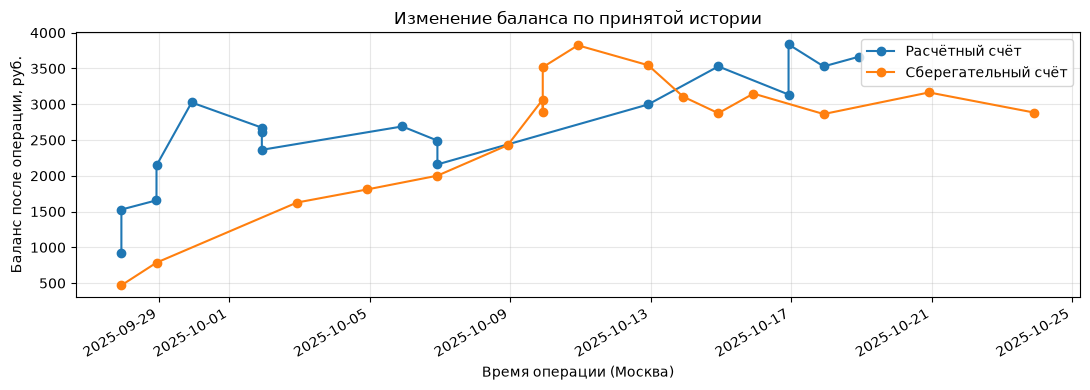

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
for account_type, label in (
    ("checking", "Расчётный счёт"), ("savings", "Сберегательный счёт"),
):
    frame = imported["csv", account_type].history_frame()
    frame["balance_after"] = frame["balance_after"].astype(float)
    frame.plot(
        x="date", y="balance_after", marker="o", label=label, ax=ax
    )
ax.set(
    title="Изменение баланса по принятой истории",
    xlabel="Время операции (Москва)", ylabel="Баланс после операции, руб.",
)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 7. Проверка импорта fail и промежуточных остатков

Временный файл дополняет реальные данные: строки перемешаны,
есть fail, превышение лимита 50%, нехватка средств и дубликат.
После проверки файл удаляется. У всех импортированных счетов
независимо проверяется остаток после каждой принятой записи.

In [8]:
# Строки перемешаны: проверяем порядок, fail, невозможные success и дубликат.
rows = [
    {
        "account_number": "ACC-9000", "account_type": "savings",
        "date": date, "operation": operation, "amount": amount,
        "status": status,
    }
    for date, operation, amount, status in (
        ("2025-01-03 12:00:00", "withdraw", 30, "success"),
        ("2025-01-01 12:00:00", "deposit", 100, "success"),
        ("2025-01-02 12:00:00", "withdraw", 20, "fail"),
        ("2025-01-02 12:00:00", "withdraw", 50, "success"),
        ("03/01/2025 13:00", "interest", 5, "success"),
        ("2025-01-04 12:00:00", "withdraw", 100, "success"),
    )
]
rows.append(rows[1].copy())
# Временный файл удалится при выходе из with.
with TemporaryDirectory() as directory:
    path = Path(directory).joinpath("history.json")
    path.write_text(json.dumps(rows), encoding="utf-8")
    extra = SavingsAccount("Роман Беляев")
    report = extra.load_history(path, "ACC-9000")
assert (report["accepted"], report["rejected"], extra.balance) == (4, 3, 55)
assert extra.history_frame()["source_row"].tolist() == [2, 3, 4, 5]
display(report["errors"])
# Независимо восстанавливаем каждый промежуточный остаток по истории.
for account in [*imported.values(), extra]:
    balance = Decimal("0.00")
    is_savings_account = account.account_type == "savings"
    for record in account.history_frame().to_dict("records"):
        is_successful = record["status"] == "success"
        is_withdrawal = record["operation"] == "withdraw"
        if is_successful:
            if is_withdrawal:
                if is_savings_account:
                    assert record["amount"] <= balance / 2
                balance -= record["amount"]
            else:
                balance += record["amount"]
        assert balance == record["balance_after"] and balance >= 0
    assert balance == account.balance

,source_row,reason
0,1,Превышен лимит снятия 50%.
1,6,Недостаточно средств.
2,7,Полный дубликат строки.
